---
title: Inferential statistics
subtitle: Using sample data to draw conclusions about a population
format:
    # typst:
    #     echo: false
    revealjs:
        smaller: true
        code-line-numbers: false
        echo: false
        include-in-header:
            - text: |
                <style>
                .reveal h1, .reveal h2, .reveal h3, .reveal h4 { text-align: center; }
                </style>
            - text: |
                <style>
                .center { text-align: center; display: block; }
                </style>
            - text: |
                <style>
                .orange { color: orange; display: block; }
                </style>
            - text: |
                <style>
                .reveal pre.sourceCode { font-size: 20px; }
                </style>

execute:
  enabled: false
editor:
    render-on-save: true
progress: true
incremental: true
slide-level: 3
jupyter: python3
---

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import t
from numpy.random import normal
from scipy.stats import norm

np.set_printoptions(linewidth=105)

mpl.rc_file('/home/njs/miniconda3/lib/python3.11/site-packages/matplotlib/mpl-data/matplotlibrc')

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

### Inferential statistics this week and next 


<div style="font-size: 1.5em;">

1.  Estimation
2.  Significance tests
3.  Linear models
4.  Multiple testing

</div>

### Estimating population parameters

### Weddell seal dive durations

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)

:::

::: {.column width="50%"}

- Marine biologists want to estimate the mean dive duration of weddell seals
- Estimated population size in Antarctica ~200,000 seals
- They cannot measure every dive of every seal in Antarctica
- They therefore measured dive duration in a sample of 10 seals from the Ross sea by attaching satellite telemetric tags

:::

::::

### Weddell seal dive durations {.smaller}

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)

:::

::: {.column width="50%"}

| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |

:::

::::

### Weddell seal dive durations {.smaller}

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)
<br>
<br>
<br>
<br>
The sample mean is denoted $\bar{x}$

:::

::: {.column width="50%"}

| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |

:::

::::

### Distribution of dive durations {.smaller}

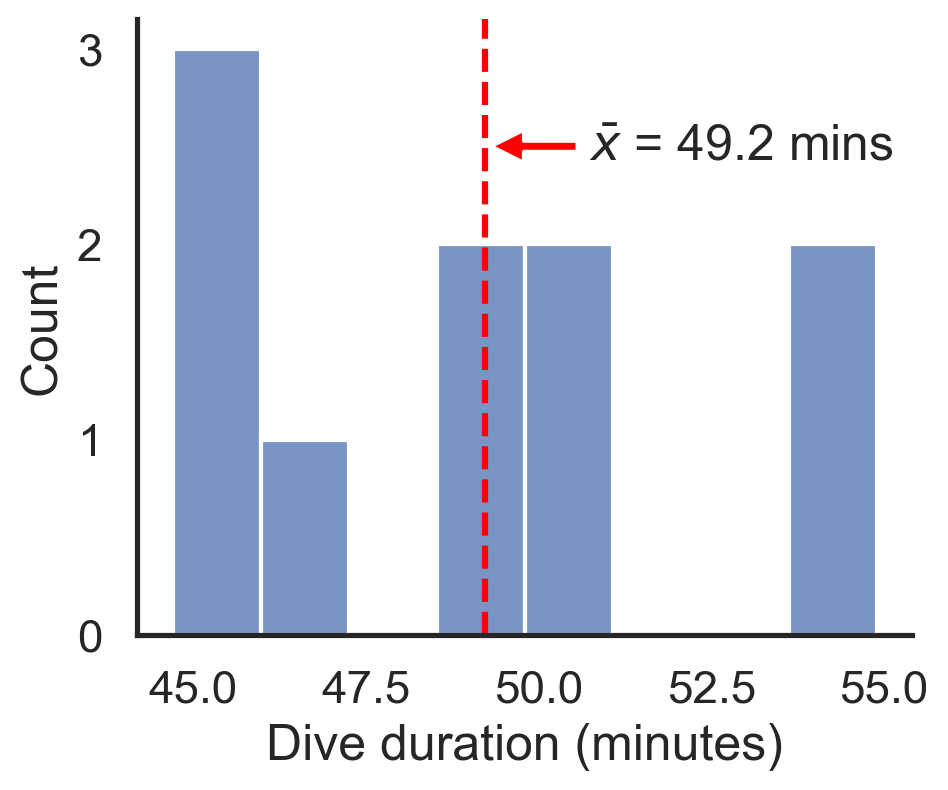

In [2]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 4))
dives = pd.read_csv('../../Datasets/weddell_seal_dives.csv')

xbar = dives['dive_duration_min'].mean()

ax = sns.histplot(dives['dive_duration_min'], bins=8, ax=ax)
ax.set_xlabel('Dive duration (minutes)')
ax.axvline(xbar, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar:.1f} mins', xy=(xbar, 2.5), xytext=(xbar + 1.5, 2.5),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');
fig.savefig('Images/fig1.png', bbox_inches='tight')

- The mean dive duration of this sample is 49.2 minutes
- But we would like to know the overall mean duration of all Weddell seal dives
- This is called the **population mean**, usually denoted $\mu$
 

### Distribution of dive durations {.smaller}

![](Images/fig1.png){fig-align="center"}

- But we can never know the population mean because we can't measure every single dive
- The best we can do is estimate it


### Distribution of dive durations {.smaller}

![](Images/fig1.png){fig-align="center"}

- A **point estimate** of the population mean is usually denoted $\hat{\mu}$
- The best point estimate of the population mean is the sample mean:

    $$\hat{\mu} = \bar{x} = 49.2\, \text{mins}$$


### A point estimate is not enough information

::: {.fragment .fade-in .center .orange}
But what if the marine biologists sampled a different set of 10 weddell seal dives
:::

:::: {.columns}

::: {.column width="20%"}

Sample 1  |
--: |
49.5 |
46.3 |
50.2 |
54.6 |
45.8 |
45.8 |
54.9 |
50.8 |
44.7 |
49.7 |
$\bar{x}_1=$ **49.2** |

:::
::: {.column width="20%" .fragment .fade-in}

Sample 2  |
--: |
44.7 |
49.3 |
48.2 |
37.4 |
38.4 |
44.2 |
41.9 |
48.6 |
42.5 |
54.3 |
$\bar{x}_2=$ **45.0** |

:::
::: {.column width="20%" .fragment .fade-in }

Sample 3 |
--: |
45.7 |
43.4 |
47.3 |
39.9 |
44.3 |
44.3 |
46.5 |
43.2 |
45.0 |
44.0 |
$\bar{x}_3=$ **44.4** |

:::
::: {.column width="40%" .fragment .fade-in  .orange}
Three different point estimates
:::
::::



### A point estimate is not enough information

- We have just one point estimate of the population mean ($\hat{\mu} =$  49.2 minutes)
- But there is some uncertainty in its value because only 10 dives were recorded
- How much uncertainty is there? For example, is it:
    - 49.2 $\pm$ 10 mins (around 39 and 59 mins)?
    - 49.2 $\pm$ 1 mins (around 48 and 50 mins)?
    - 49.2 $\pm$ 0.1 mins (around 49.1 and 49.3 mins)?

- We need to quantify the uncertainty in dive durations

### A point estimate is not enough information

- This uncertainty is called **sampling error**
    - So you can ask, how much error is there in the point estimate?
- The inverse of error is **precision**. 
    - So you can also ask, how precise is the point estimate?
- In conclusion, the full information we require is:
    - a point estimate of the population mean
    - the error (or precision) associated with that estimate
- [What determines the size of the error, and how do we calculate it?]{.orange}

### The error in the estimate of a population mean

The error in the estimate of the population mean is called **Standard error of the mean**.

::: {.fragment}
$$
\begin{align*}
\text{SEM} &= \frac{\text{Standard deviation of the sample}}{\text{Square root of number of observations}} \\
\text{SEM} &= \frac{s}{\sqrt{n}}
\end{align*}
$$
:::
::: {.fragment .center .orange}
Where does this formula come from?
:::


### The sampling distribution

:::: {.columns}
::: {.column width="50%"}

If you had an infinite number of samples, each with $n$ observations, the distribution of their means is called a sampling distribution.

::: {.fragment}
The mean of our single sample is one of the infinite number of means.
:::

:::
::: {.column width="50%"}

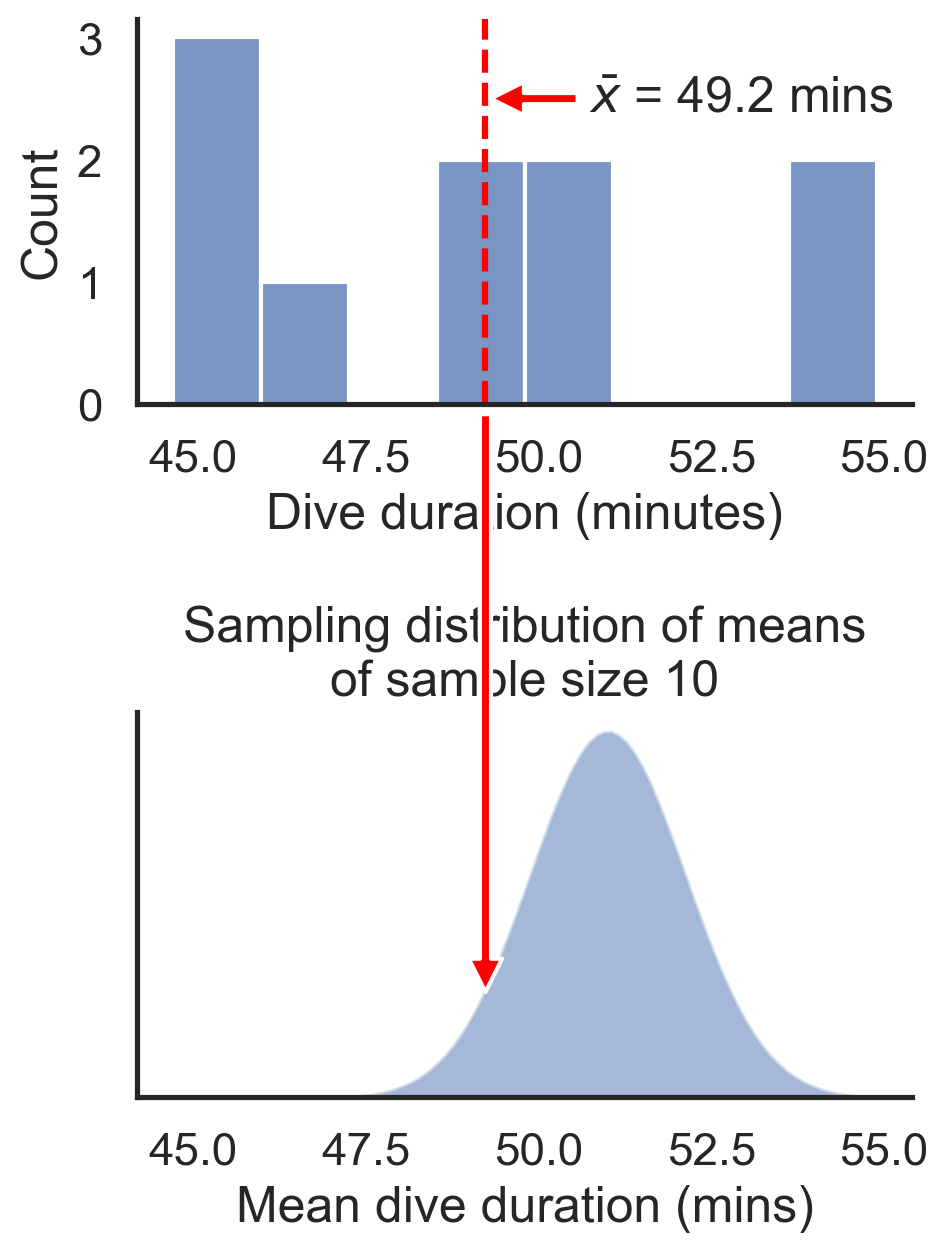

In [3]:
#| fig-align: center

fig, axs = plt.subplots(2, 1, figsize=(5, 7))
fig.subplots_adjust(hspace=0.8)
ax = axs[0]
ax = sns.histplot(dives['dive_duration_min'], bins=8, ax=ax)
ax.set_xlabel('Dive duration (minutes)')
ax.axvline(xbar, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar:.1f} mins', xy=(xbar, 2.5), xytext=(xbar + 1.5, 2.5),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False);

ax = axs[1]

s = dives['dive_duration_min'].std()

mu = 51
sem_e = s/np.sqrt(10)
xt = np.linspace(mu-5*sem_e, mu+5*sem_e, 100)
yt = norm.pdf(xt, mu, sem_e)
ax.fill_between(xt, 0, yt, alpha=0.5)

ax.set_xlabel('Mean dive duration (mins)')
ax.set_xlim(axs[0].get_xlim())
ax.set_yticks([])
ax.set_ylabel('')
ax.set_ylim(0, ax.get_ylim()[1])
ax.set_title('Sampling distribution of means\nof sample size 10');

ax.annotate('', xy=(xbar, 0.1), xytext=(xbar, 0.65), zorder=1000, arrowprops=dict(facecolor='red', edgecolor='w'), va='center');


:::
::::

### Interactive plot of the sampling distribution

The notebook [estimate.ipynb](estimate.ipynb) has an interactive plot of the sampling distribution.

### Simulating a sampling distribution

- In the class notebook you can try and create a sampling distribution using Monte-Carlo simulation

### The final estimate with error

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}
| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |
:::
::::

### The final estimate with error

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}


In [4]:
#| echo: true
#| output-location: fragment

dives = pd.read_csv('../../Datasets/weddell_seal_dives.csv')

n = dives['dive_duration_min'].count()
xbar = dives['dive_duration_min'].mean()
s = dives['dive_duration_min'].std()

# Either
sem = s/np.sqrt(n)
# or
sem = dives['dive_duration_min'].sem()

print(f'n: {n}')
print(f'mean: {xbar:.2f} mins')
print(f'std: {s:.2f} mins')
print(f'SEM: {sem:.2f} mins')

n: 10
mean: 49.23 mins
std: 3.61 mins
SEM: 1.14 mins


:::
::::

### The final estimate with error

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}

The estimated mean dive duration of Weddell seals is

$\hat{\mu}=$ `{python} f'{xbar:.1f} ± {sem:.1f}'` mins

Average dive durations of Weddell seals is 49 minutes plus or minus 1 minute.
:::
::::

### A common alternative: the 95% CI

::: {.fragment}

$$\hat{\mu} = \bar{x}\pm\text{SEM}$$

is just one way of reporting a point estimate of the population mean with error.

:::
::: {.fragment}

$$\hat{\mu} = \bar{x}\pm t_{n-1}\times\text{SEM}$$

is another common way and is called a 95% confidence interval (CI)

:::

### A common alternative: the 95% CI

$$\hat{\mu} = \bar{x}\pm t_{n-1}\times\text{SEM}$$

The factor $t_{n-1}$ is a correction factor for small sample sizes.

*n* | $t_{n-1}$
--: | --:
2 | 12.71
5 | 2.78
10 | 2.26
20 | 2.09
50 | 2.01
100 | 1.98
500+ | 1.96


### A common alternative: the 95% CI

##### A rule of thumb: 

For samples with more than 20 observations $t_{n-1}$ is about 2, i.e.,
 
$$\hat{\mu} = \bar{x}\pm 2\times\text{SEM}$$

::: {.fragment}
For large enough samples, the 95% CI is about two times larger than the standard error.
:::

### A common alternative: the 95% CI

The code to calculate $t_{n-1}$ is

In [5]:
#| echo: true
#| output-location: fragment

from scipy.stats import t

t_df = t.ppf(0.975, df=9)

print(f't_df = {t_df:.2f}')

t_df = 2.26


::: {.fragment}
`df` stands for "degrees of freedom". In this case it is one less than the sample size. 
:::


### A common alternative: the 95% CI

For *n* = 10, $t_{9}=$ `{python} f'{t_df:.2f}'`

::: {.fragment}
95% CI are usually written as a range from the low bound to the high bound. 
:::

- low bound = $\bar{x} - t_{n-1}\times\text{SEM}$
- high bound = $\bar{x} + t_{n-1}\times\text{SEM}$

::: {.fragment}

In [6]:
#| echo: true
#| output-location: fragment

ci_low = xbar - t_df * sem
ci_high = xbar + t_df * sem

print(f'95% CI: [{ci_low:.1f}, {ci_high:.1f}] mins')


95% CI: [46.6, 51.8] mins


:::

### A common alternative: the 95% CI

- The 95% CI of dive durations is [`{python} f'{ci_low:.1f}'`, `{python} f'{ci_high:.1f}'`] mins.

- Many statistical software packages automatically calculate SEM and 95% CIs for you.

### Visualising point estimates and their errors {auto-animate=true}

- Errors are graphically represented as error bars
- Barplots are a common method

::: {.fragment}

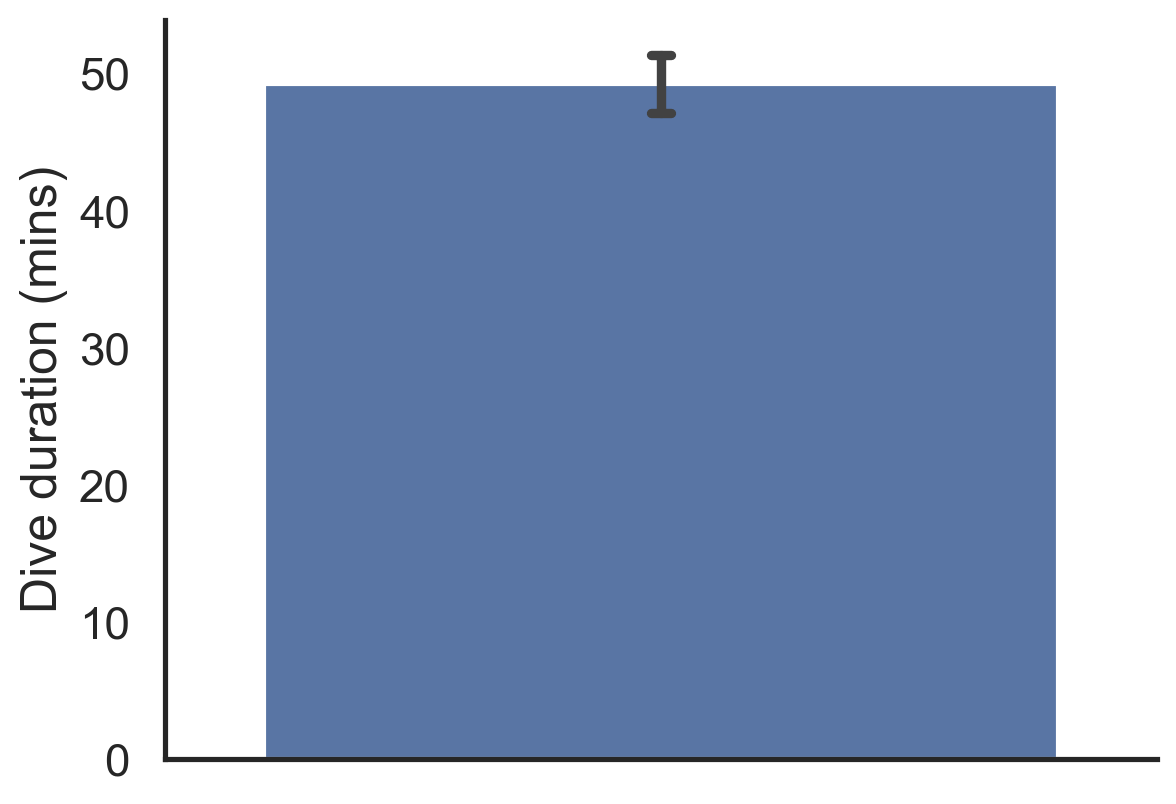

In [7]:
#| echo: true
#| fig-align: center
#| output-location: fragment
#| data-id: graph2

ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');

:::

### Error bars in a bar plot

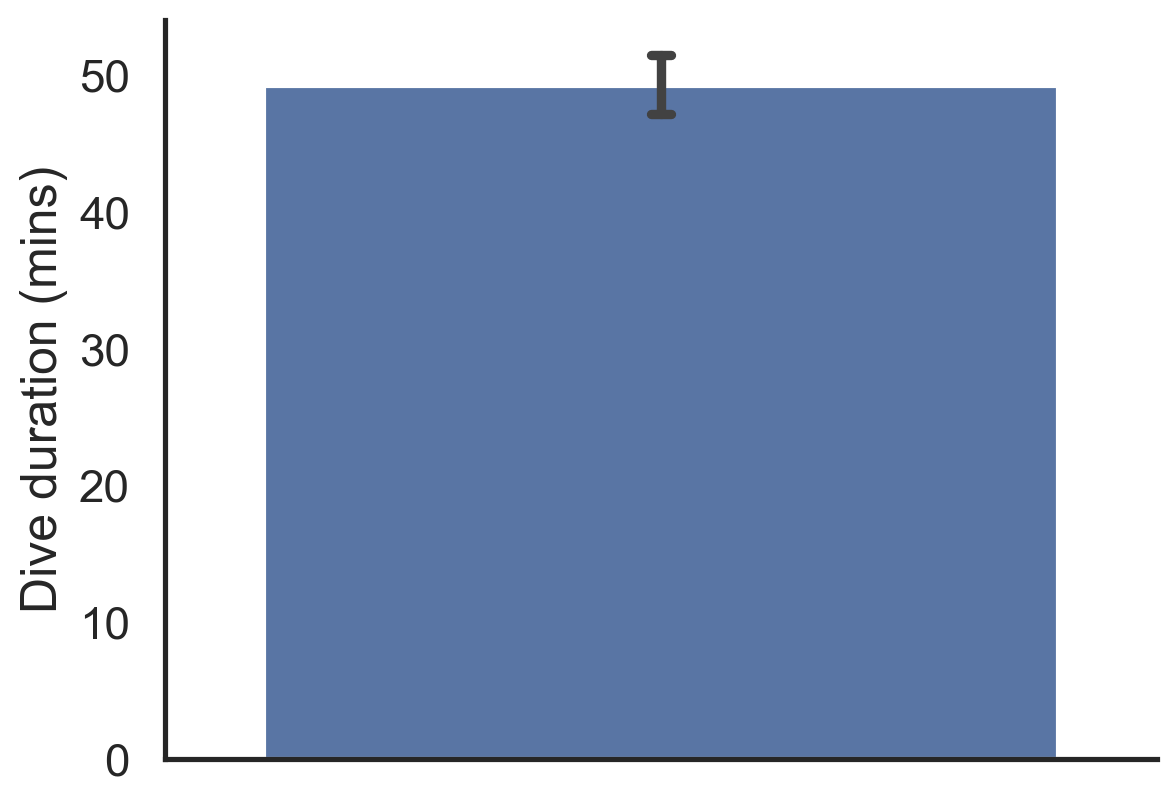

In [8]:
#| fig-align: center

ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');

A bar plot creates a bar with the bottom at zero and the top at the point estimate. The errorbar extends from the low bound to the high bound of the 95% CI.


### Error bars in a bar plot

These plots are more useful when comparing things. Dive durations of different seal species, for example.

In [9]:
x1 = normal(90, 20, size=10)
x2 = normal(50, 10, size=10)
x3 = normal(30, 10, size=10)
x4 = normal(17, 5, size=10)
x5 = normal(12, 4, size=10)
dives_cmp = pd.concat([
    pd.DataFrame({'dive_duration_min': x1, 'group': 'Elephant seal'}),
    pd.DataFrame({'dive_duration_min': x2, 'group': 'Weddell seal'}),
    pd.DataFrame({'dive_duration_min': x3, 'group': 'Harbor seal'}),
    pd.DataFrame({'dive_duration_min': x4, 'group': 'Leopard seal'}),
    pd.DataFrame({'dive_duration_min': x5, 'group': 'Crabeater seal'})
], ignore_index=True)

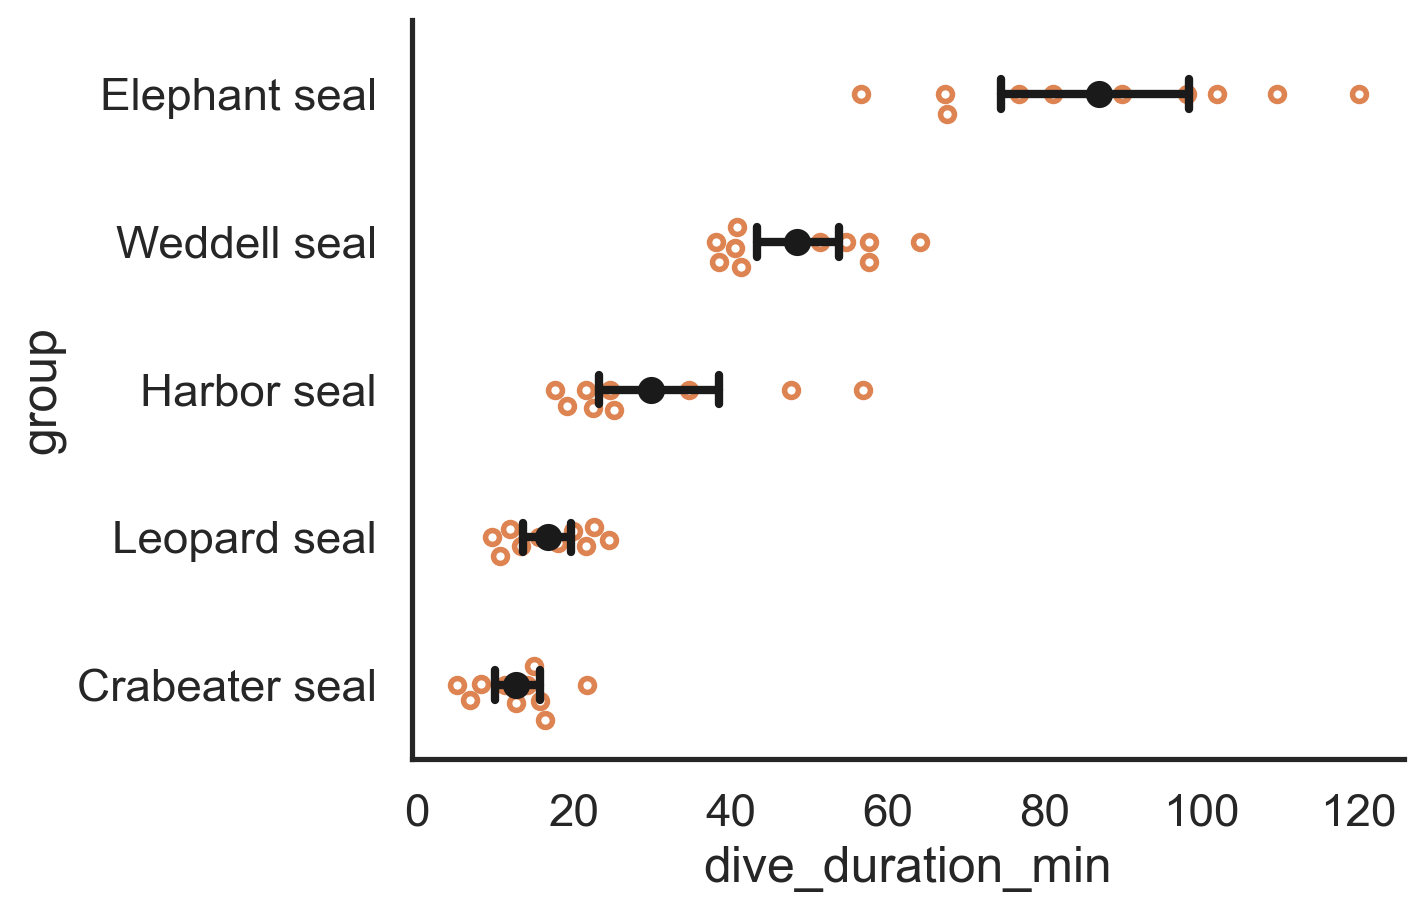

In [10]:
#| output: false

# make this here to get the xlimit extent, but do not show it until later

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
xlims = ax.get_xlim()

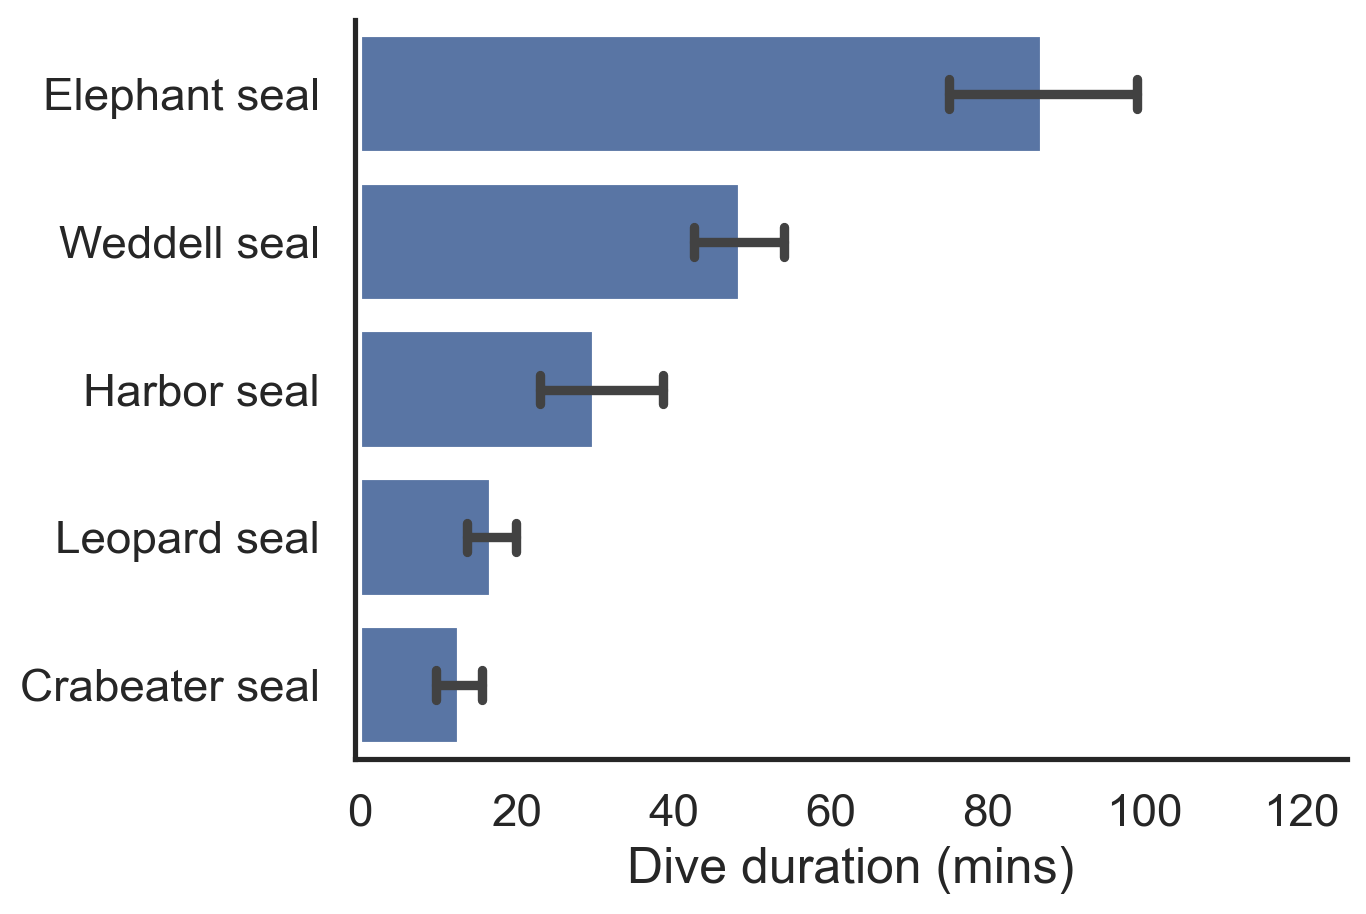

In [11]:
#| output: true
#| fig-align: center

ax = sns.barplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');


### Error bars in a point plot

A point plot just plots a circle at the point estimate. This gives a less cluttered figure than a bar plot.

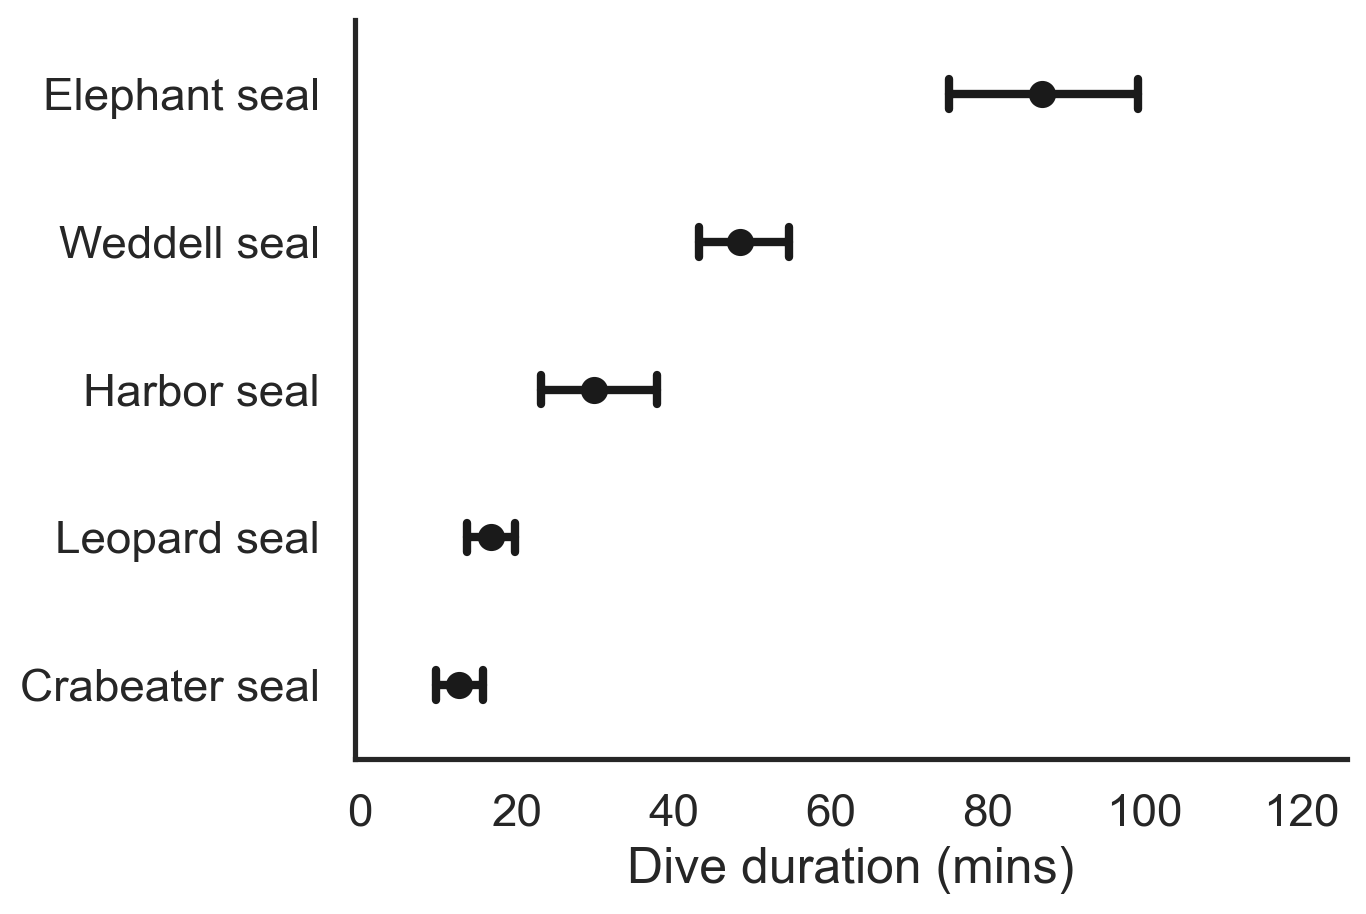

In [12]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');

### Include the data

If there are not too many data including them can be useful to see the distribution of the data 

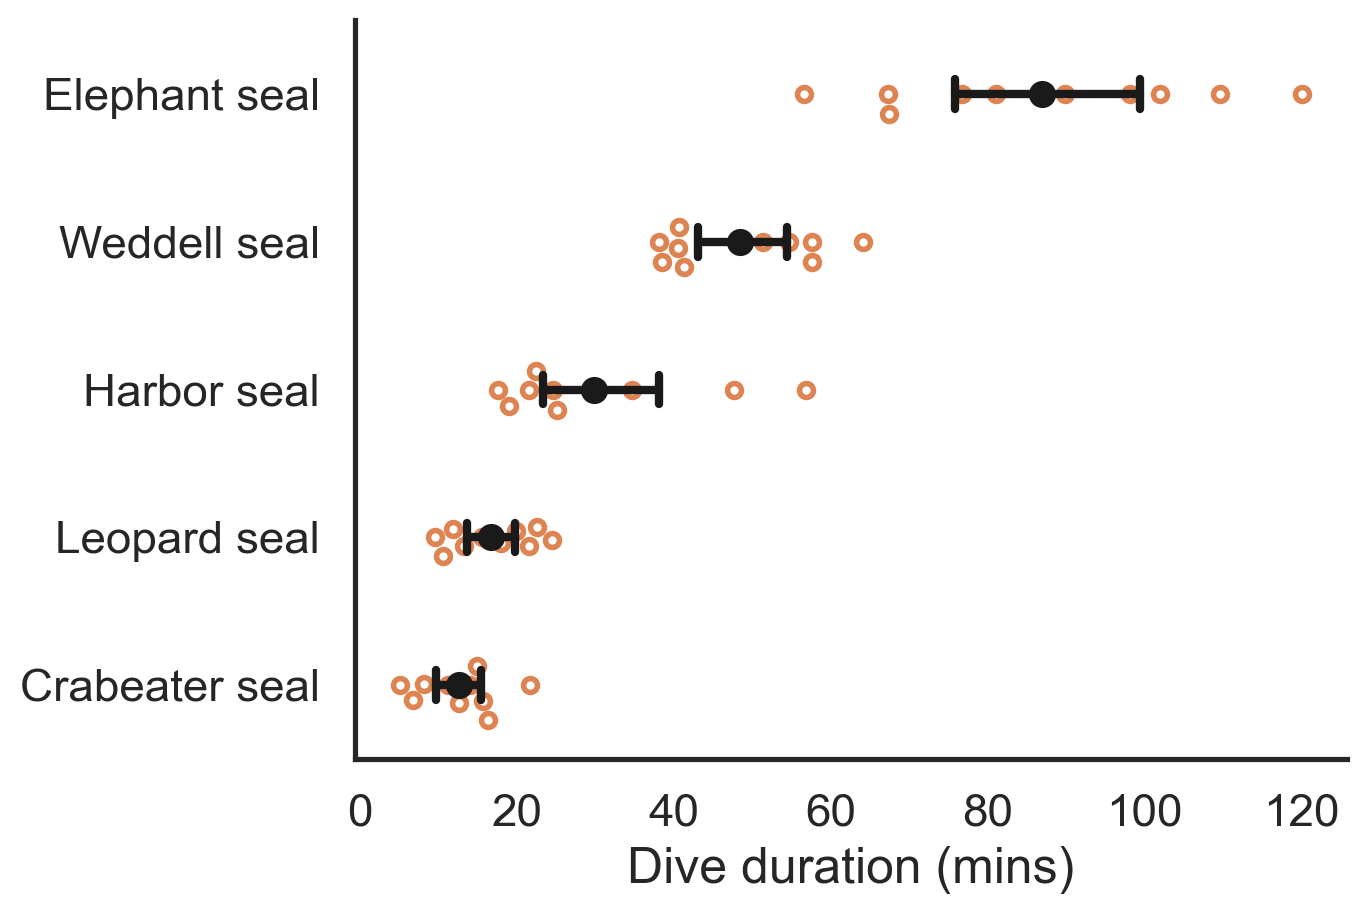

In [13]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)')
ax.set_ylabel('');

### Error bars in a point plot

::: {.callout-important}
Always state in the figure caption what errorbars represent (SEM, 95% CI) so that readers know how to interpret them.
:::

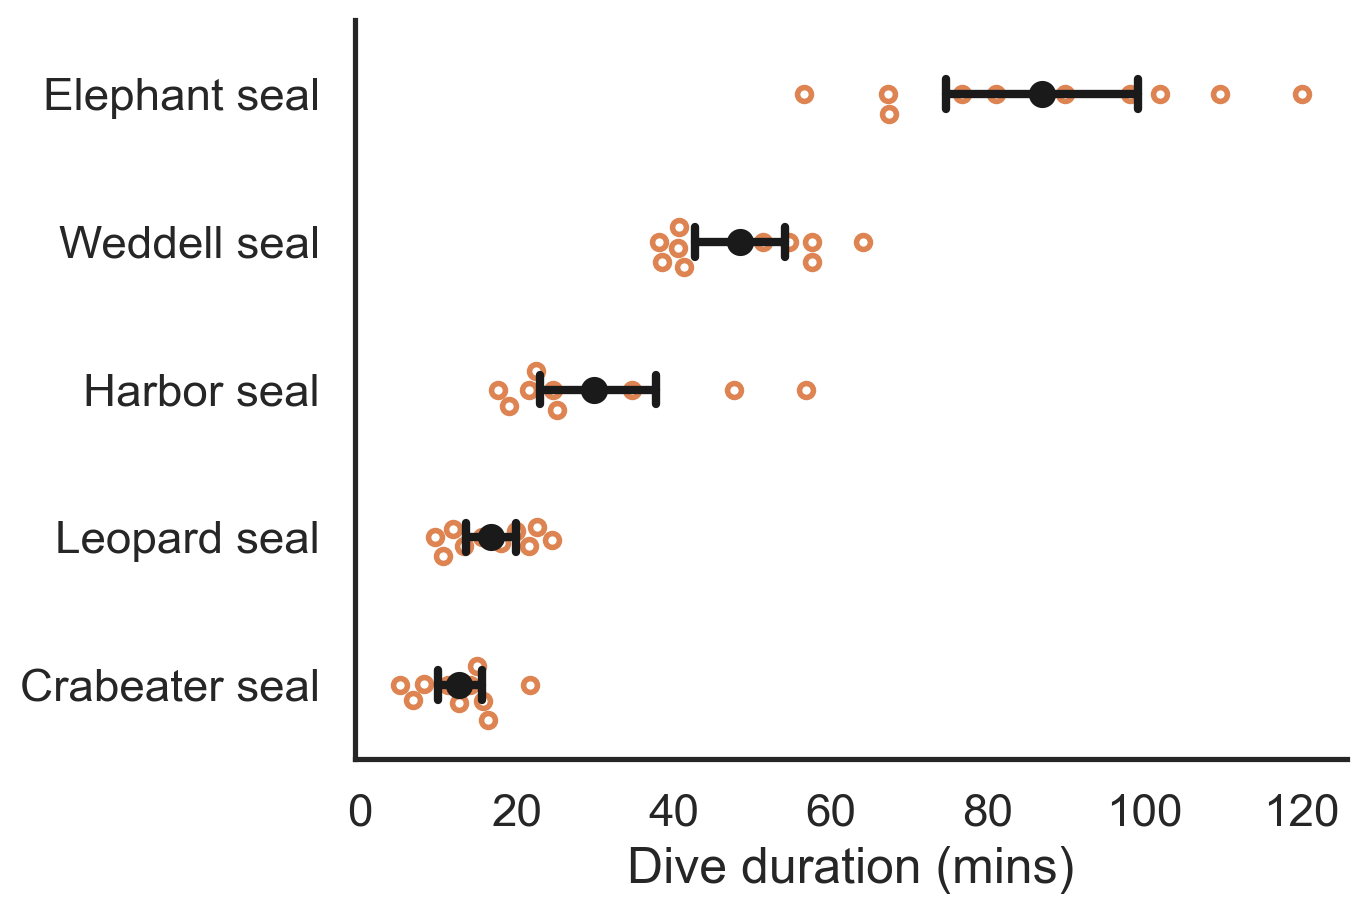

In [14]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');

### Conclusion

::: {.center}
Estimate of population parameter = Point estimate ± Standard error
:::

::: {.fragment .center}
For example, the estimate of a population mean:

$$\hat{\mu} = \bar{x} \pm \frac{s}{\sqrt n}$$
:::



### This week's class notebook

Three questions:

1. **Weddell seal dive durations**: 
    
    - The same analysis as in the lecture but with a larger data set

2. **Evolution of ground finch beak depths**:
    
    - Estimate the **difference** in the means of two populations
    - This is a little more complicated and is a prelude to Friday's material

3. **Proportion of hospital patients with vancomycin-resistant intestinal *Enterococcus* bacteria**
    
    - How to estimate a population proportion from a sample of data
    - Method 1: By using a formula for the standard error of the proportion
    - Method 2: By using Monte-Carlo simulation of the sampling distribution of a proportion
